# ASSIGNMENT-2 - DL 2026


Tanushka Sonde- 23110332







# Q1. Softer targets

### setup

In [ ]:
import copy
import csv
import random
import re
import numpy as np
import torch
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader, TensorDataset
import matplotlib.pyplot as plt


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

device = "cuda" if torch.cuda.is_available() else "cpu"

### a)  Train and report: 2 marks

In [ ]:
# Data
transform = transforms.ToTensor()
all_training = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)
g = torch.Generator().manual_seed(42)
order = torch.randperm(60000, generator=g).tolist()
train_data = Subset(all_training, order[:6000])
val_data = Subset(all_training, order[6000:7000])

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.9MB/s]


In [ ]:
val_loader = DataLoader(val_data, batch_size=128, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False, num_workers=0)

In [ ]:
def make_train_loader(batch_size=128):
    return DataLoader(train_data, batch_size=batch_size, shuffle=True,
                      num_workers=0, drop_last=False,
                      generator=torch.Generator().manual_seed(42))

def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    )


In [ ]:
# Evaluation helpers
hard_eval = nn.CrossEntropyLoss(label_smoothing=0.0, reduction="sum")

@torch.no_grad()
def evaluate(model, loader):
    """Returns mean hard CE loss, accuracy, and per-sample confidences."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    confs = []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += hard_eval(logits, y).item()
        correct += (logits.argmax(dim=-1) == y).sum().item()
        n += y.numel()
        confs.append(torch.softmax(logits, dim=-1).max(dim=-1).values.cpu())
    return total_loss / n, correct / n, torch.cat(confs)


In [ ]:
# Training
def train_model(init_state, train_criterion, epochs=10, lr=1e-3):
    model = make_model().to(device)
    model.load_state_dict(init_state)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    train_loader = make_train_loader()

    best_val = float("inf")
    best_epoch = None
    best_weights = None

    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = train_criterion(model(x), y)
            loss.backward()
            opt.step()

        val_loss, val_acc, _ = evaluate(model, val_loader)   # validation always uses hard loss
        print(f"  epoch {epoch:2d} | val CE {val_loss:.4f} | val acc {val_acc:.4f}")
        if val_loss < best_val:            # strict '<' keeps the earlier epoch on a tie
            best_val = val_loss
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    test_loss, test_acc, test_conf = evaluate(model, test_loader)
    return {
        "model": model,
        "epoch": best_epoch,
        "val_loss": best_val,
        "test_loss": test_loss,
        "test_acc": test_acc,
        "test_conf": test_conf,
    }

In [ ]:
# Identical initial weights for both models
set_seed(42)
init_state = copy.deepcopy(make_model().state_dict())

criteria = {
    "hard (ls=0.0)": nn.CrossEntropyLoss(label_smoothing=0.0),
    "soft (ls=0.1)": nn.CrossEntropyLoss(label_smoothing=0.1),
}

results = {}
for name, crit in criteria.items():
    print(f"Training {name}")
    set_seed(42)   # same seed state at the start of each run
    results[name] = train_model(init_state, crit)


Training hard (ls=0.0)
  epoch  1 | val CE 0.7546 | val acc 0.7300
  epoch  2 | val CE 0.6328 | val acc 0.7820
  epoch  3 | val CE 0.5530 | val acc 0.8020
  epoch  4 | val CE 0.5328 | val acc 0.8170
  epoch  5 | val CE 0.4974 | val acc 0.8360
  epoch  6 | val CE 0.4999 | val acc 0.8210
  epoch  7 | val CE 0.4798 | val acc 0.8370
  epoch  8 | val CE 0.4593 | val acc 0.8500
  epoch  9 | val CE 0.4639 | val acc 0.8290
  epoch 10 | val CE 0.4779 | val acc 0.8320
Training soft (ls=0.1)
  epoch  1 | val CE 0.8085 | val acc 0.7390
  epoch  2 | val CE 0.7086 | val acc 0.7870
  epoch  3 | val CE 0.6464 | val acc 0.8060
  epoch  4 | val CE 0.6200 | val acc 0.8170
  epoch  5 | val CE 0.5806 | val acc 0.8360
  epoch  6 | val CE 0.5776 | val acc 0.8320
  epoch  7 | val CE 0.5686 | val acc 0.8410
  epoch  8 | val CE 0.5521 | val acc 0.8510
  epoch  9 | val CE 0.5565 | val acc 0.8370
  epoch 10 | val CE 0.5553 | val acc 0.8330


In [ ]:
print("\n=== Q1(a) Results ===")
print(f"{'model':<15}{'sel. epoch':>11}{'test acc':>10}{'mean conf':>11}")
for name, r in results.items():
    print(f"{name:<15}{r['epoch']:>11}{r['test_acc']:>10.4f}{r['test_conf'].mean().item():>11.4f}")



=== Q1(a) Results ===
model           sel. epoch  test acc  mean conf
hard (ls=0.0)            8    0.8226     0.8070
soft (ls=0.1)            8    0.8248     0.7145


### b) Compare confidence: 1 mark

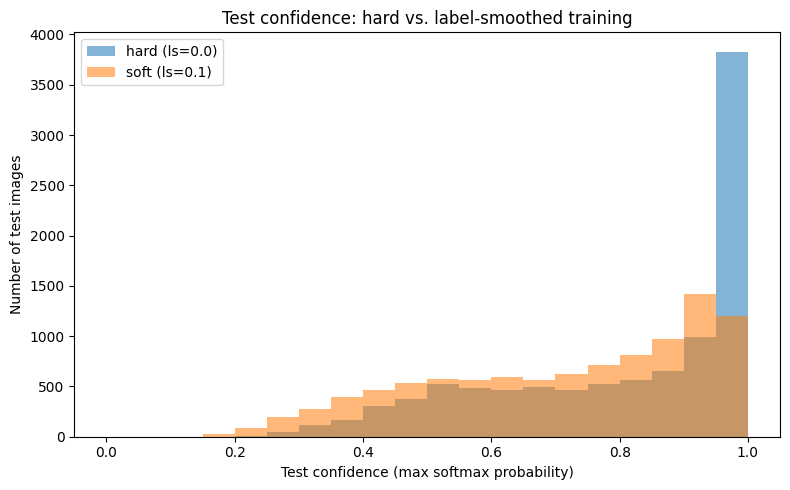

In [ ]:
bins = np.linspace(0, 1, 21)   # 20 equal-width bins on [0, 1]
plt.figure(figsize=(8, 5))
for name, r in results.items():
    plt.hist(r["test_conf"].numpy(), bins=bins, alpha=0.55, label=name)
plt.xlabel("Test confidence (max softmax probability)")
plt.ylabel("Number of test images")
plt.title("Test confidence: hard vs. label-smoothed training")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
for name, r in results.items():
    c, _ = np.histogram(r["test_conf"].numpy(), bins=bins)
    print(f"{name}: 0.95-1.0 bin = {c[-1]}, 0.90-0.95 bin = {c[-2]}, "
          f"mean conf = {r['test_conf'].mean():.4f}")

hard (ls=0.0): 0.95-1.0 bin = 3830, 0.90-0.95 bin = 993, mean conf = 0.8070
soft (ls=0.1): 0.95-1.0 bin = 1200, 0.90-0.95 bin = 1418, mean conf = 0.7145


### c) Explain: 2 marks

Accuracy was essentially unchanged (82.26% for the hard model vs 82.48% for the smoothed model, a gap of about 22 of 10,000 test images, which is likely within single-seed noise), while mean test confidence fell clearly from 0.807 to 0.715. The histogram shows the cause: the hard model puts 3,830 test images in the 0.95–1.0 bin versus only 1,200 for the smoothed model, whose mass moves into the 0.90–0.95 bin (1,418 vs 993) and lower. With one-hot targets, cross-entropy keeps decreasing as the true-class probability approaches 1, so training keeps pushing logits apart, whereas with the soft target (0.91 for the true class, 0.01 for each other class) the loss is lowest when the true-class probability is 0.91, so going beyond it increases the loss and the pressure toward extreme confidence disappears. Because the argmax barely changes, accuracy stays similar, but in this short 10-epoch run smoothing moved the model from roughly calibrated (0.807 confidence vs 0.823 accuracy) to underconfident (0.715 vs 0.825).

# Q2. Predict the next letter

In [ ]:
with open("/content/names.csv", encoding="utf-8-sig", newline="") as f:
    names = sorted({
        re.sub(r"[^a-z]", "", row["Name"].lower())
        for row in csv.DictReader(f)
    } - {""})
assert len(names) == 6478

g = torch.Generator().manual_seed(42)
order = torch.randperm(len(names), generator=g).tolist()
train_names = [names[i] for i in order[:5182]]
val_names   = [names[i] for i in order[5182:5829]]
test_names  = [names[i] for i in order[5829:]]
assert (len(train_names), len(val_names), len(test_names)) == (5182, 647, 649)

stoi = {ch: i for i, ch in enumerate("-abcdefghijklmnopqrstuvwxyz")}
itos = {i: ch for ch, i in stoi.items()}

In [ ]:
#creating the train, test and validation set
def build(name_list, w=3):
    X,y= [],[]
    for n in name_list:
        padded= [stoi["-"]]* w + [stoi[c] for c in n + "-"]
        for j in range(len(n)+1):
            X.append(padded[j:j+w])
            y.append(padded[j+w])
    return torch.tensor(X),torch.tensor(y)

Xtr,Ytr= build(train_names)
Xva,Yva= build(val_names)
Xte,Yte= build(test_names)
print(len(Xtr),len(Xva),len(Xte))         #each should equal to sum(len(name)+1)
print(build(["ana"]))

38230 4719 4703
(tensor([[ 0,  0,  0],
        [ 0,  0,  1],
        [ 0,  1, 14],
        [ 1, 14,  1]]), tensor([ 1, 14,  1,  0]))


In [ ]:
# defining the model
set_seed(42)
embedding = nn.Embedding(27, 2).to(device)
network = nn.Sequential(
    nn.Linear(6, 32),
    nn.ReLU(),
    nn.Linear(32, 27),
    ).to(device)
optimizer= torch.optim.Adam(list(embedding.parameters()) + list(network.parameters()), lr=1e-3)
ce= nn.CrossEntropyLoss()

#making predictions
def forward(ctx):
    return network(embedding(ctx).reshape(-1, 6))

# saving both embedding and network
def save():
    return copy.deepcopy(embedding.state_dict()), copy.deepcopy(network.state_dict())

@torch.no_grad()
def loss(X, Y):
    embedding.eval()
    network.eval()
    total= nn.functional.cross_entropy(forward(X.to(device)), Y.to(device), reduction="sum")
    return total.item()/len(Y)             # nats per predicted token

### a) Train and evaluate

In [ ]:
# training
train_loader= DataLoader(
    TensorDataset(Xtr, Ytr), batch_size=256, shuffle=True,
    num_workers=0, drop_last=False,
    generator=torch.Generator().manual_seed(42),
)

train_loss, val_loss= [],[]
best_val, best_epoch, best_weights= float("inf"), None, None

for epoch in range(1, 21):
    embedding.train()
    network.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        batch_loss= ce(forward(xb), yb)
        optimizer.zero_grad()
        batch_loss.backward()
        optimizer.step()
    tr, va= loss(Xtr, Ytr), loss(Xva, Yva)
    train_loss.append(tr)
    val_loss.append(va)
    if va< best_val:
        best_val, best_epoch, best_weights= va, epoch, save()
    print(f"epoch {epoch:2d}  train loss{tr:.4f}  val loss{va:.4f}")

embedding.load_state_dict(best_weights[0])
network.load_state_dict(best_weights[1])
test_loss= loss(Xte, Yte)
print(f"selected epoch {best_epoch} | best val loss {best_val:.4f} | test loss {test_loss:.4f} nats/token")

epoch  1  train loss2.7494  val loss2.7612
epoch  2  train loss2.6005  val loss2.6139
epoch  3  train loss2.5256  val loss2.5366
epoch  4  train loss2.4756  val loss2.4825
epoch  5  train loss2.4374  val loss2.4414
epoch  6  train loss2.4069  val loss2.4090
epoch  7  train loss2.3855  val loss2.3855
epoch  8  train loss2.3690  val loss2.3669
epoch  9  train loss2.3563  val loss2.3549
epoch 10  train loss2.3451  val loss2.3421
epoch 11  train loss2.3362  val loss2.3332
epoch 12  train loss2.3296  val loss2.3249
epoch 13  train loss2.3216  val loss2.3194
epoch 14  train loss2.3161  val loss2.3142
epoch 15  train loss2.3108  val loss2.3093
epoch 16  train loss2.3057  val loss2.3027
epoch 17  train loss2.3007  val loss2.2979
epoch 18  train loss2.2971  val loss2.2949
epoch 19  train loss2.2935  val loss2.2908
epoch 20  train loss2.2898  val loss2.2883
selected epoch 20 | best val loss 2.2883 | test loss 2.3217 nats/token


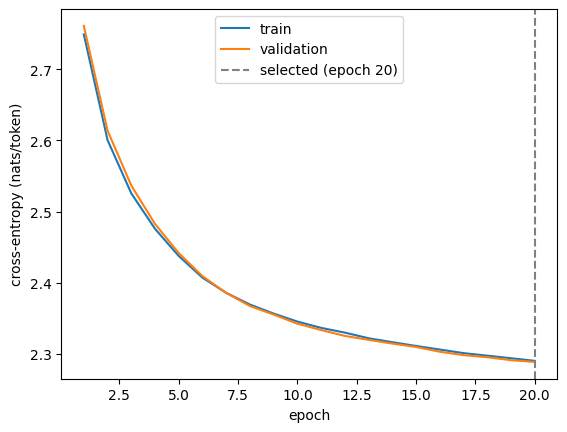

In [ ]:
#plotting train and validation loss vs. epoch
#selected epoch is marked with a dashed line

import matplotlib.pyplot as plt

plt.plot(range(1, 21), train_loss, label="train")
plt.plot(range(1, 21), val_loss, label="validation")
plt.axvline(best_epoch, ls="--", c="gray", label=f"selected (epoch {best_epoch})")
plt.xlabel("epoch"); plt.ylabel("cross-entropy (nats/token)"); plt.legend(); plt.show()

### Generate names

In [ ]:
# generating names
@torch.no_grad()
def generate(temperature=None):  # None refers to greedy
    embedding.eval()
    network.eval()
    ctx, out= [0,0,0], []
    for _ in range(20):
        logits= forward(torch.tensor([ctx], device=device))
        if temperature is None:
            nxt= logits.argmax(dim=-1).item()
        else:
            probs= torch.softmax(logits/temperature, dim=-1)
            nxt= torch.multinomial(probs, num_samples=1).item()
        if nxt == 0:
            return "".join(out), False        # ended with end token
        out.append(itos[nxt])
        ctx= ctx[1:] + [nxt]
    return "".join(out), True                 # hit the 20-letter limit

def show(name, hit_limit):
    tag = "  <empty>" if name == "" else ""
    tag += "  <hit 20-letter limit>" if hit_limit else ""
    print(f"  {name!r}{tag}")

print("greedy:")
for _ in range(5):
  show(*generate(None))
for T in [0.5, 1, 2]:
    set_seed(43)
    print(f"temperature {T}:")
    for _ in range(5):
        show(*generate(T))

greedy:
  'sara'
  'sara'
  'sara'
  'sara'
  'sara'
temperature 0.5:
  'ran'
  'ran'
  'bach'
  'sanra'
  'paj'
temperature 1:
  'rer'
  'rainbach'
  'suprame'
  'julinkibaninditah'
  'kosh'
temperature 2:
  'ref'
  'roinbachcvmprach'
  'julitkobaiinumtah'
  'vosh'
  'paf'


### c) explanation

* Greedy generation repeats the same name from the same start because  greedy takes the argmax at every step, so the same context (---) always gives the same first letter, then the same second, and so on. That is why the output is always sara. The name is fully determined by the start tokens, with no randomness involved.

* Sampling at temperature 0.5, the highest-probability characters become much more likely, so generated names tend to be more predictable and similar to patterns seen during training. the samples stay short (ran, bach, sanra, paj) and even repeat (ran repeats twice).

* At temperature 1 the samples come from the model's learned distribution and get more varied, including longer outputs like julinkibaninditah.

* At temperature 2 the distribution is flattened, probabilities become more spread out, so less-likely characters have a higher chance of being selected. The names become less plausible (roinbachcvmprach, julitkobaiinumtah), although a few short ones like ref and paf still appear.

There were no empty outputs and none hit the 20-letter limit.

Samples look correlated across temperatures. rainbach (T=1) and roinbachcvmprach (T=2) are similar, as are julinkibaninditah and julitkobaiinumtah. It is because we reset seed 43 before each group, so every temperature uses the same random stream, and similar probabilities lead to similar choices. It also means the difference between groups reflects temperature

# Ques 3 What does the causal mask do?

In [ ]:
import torch
import matplotlib.pyplot as plt

E = torch.tensor([[1.0, 0.0],
                  [0.0, 1.0],
                  [1.0, 1.0]])
W_q = torch.eye(2)
W_k = torch.eye(2)
W_v = torch.eye(2)
W_o = torch.eye(2)

### (a) Calculate attention

In [ ]:
def attention(E, causal):
    Q = E @ W_q
    K = E @ W_k
    V = E @ W_v
    scores = (Q @ K.transpose(-2, -1)) / (2 ** 0.5)
    if causal:
        future = torch.triu(torch.ones_like(scores, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(future, float("-inf"))
    A = torch.softmax(scores, dim=-1)
    updated = E + (A @ V) @ W_o
    return A, updated

In [ ]:
res= {}
for name, causal in [("no mask", False), ("causal", True)]:
    A, upd= attention(E, causal)
    res[name]= A
    print(f"--- {name} ---\nA =\n{A}\nupdated =\n{upd}")
    print("Check on whether rows sum to 1:", torch.allclose(A.sum(-1), torch.ones(3)))
    if causal:
        print("Check on whether future weights are zero:", bool((A[torch.triu(torch.ones(3, 3), 1).bool()] == 0).all()))

--- no mask ---
A =
tensor([[0.4011, 0.1978, 0.4011],
        [0.1978, 0.4011, 0.4011],
        [0.2483, 0.2483, 0.5035]])
updated =
tensor([[1.8022, 0.5989],
        [0.5989, 1.8022],
        [1.7517, 1.7517]])
Check on whether rows sum to 1: True
--- causal ---
A =
tensor([[1.0000, 0.0000, 0.0000],
        [0.3302, 0.6698, 0.0000],
        [0.2483, 0.2483, 0.5035]])
updated =
tensor([[2.0000, 0.0000],
        [0.3302, 1.6698],
        [1.7517, 1.7517]])
Check on whether rows sum to 1: True
Check on whether future weights are zero: True


Both runs return rows that sum to 1. In the causal run the three entries above the diagonal are exactly 0, so row 1 of updated ([0.3302, 1.6698]) is built only from tokens 0 and 1.

### b) Show the mask

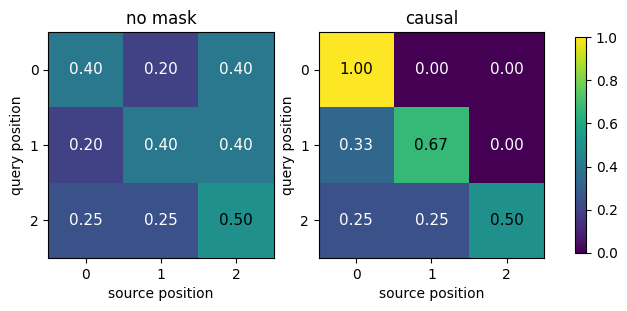

In [ ]:
fig,axes= plt.subplots(1, 2, figsize=(8, 3.5))
for ax, (name, A) in zip(axes, res.items()):
    im= ax.imshow(A, vmin=0, vmax=1, cmap="viridis")
    ax.set_title(name)
    ax.set_xlabel("source position"); ax.set_ylabel("query position")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    for i in range(3):
        for j in range(3):
            v= A[i, j].item()
            ax.text(j,i, f"{v:.2f}", ha="center", va="center",
                    color="black" if v > 0.5 else "white", fontsize=11)

fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

In the unmasked run, every query row spreads weight over all three source positions, including future ones (row 0 gives 0.40 to position 2). In the causal run, the entries above the diagonal are exactly 0.00 and each row renormalises over the allowed positions (row 1 becomes 0.33/0.67, row 0 becomes 1.00), while row 2 is identical in both runs because it can already see every position.

### c) Change a future token

In [ ]:
changed_E = E.clone()
changed_E[2] = torch.tensor([4.0, 4.0])
for name,causal in [("no mask", False),("causal", True)]:
    _, u0= attention(E,causal)
    _, u1= attention(changed_E,causal)
    print(name, "largest absolute change in first two rows:", (u0[:2] - u1[:2]).abs().max().item())

no mask largest absolute change in first two rows: 2.844011068344116
causal largest absolute change in first two rows: 0.0


* In the causal run, the scores for future positions are set to −inf before softmax, so rows 0 and 1 give exactly zero attention weight to position 2. Each row of updated is the token's own vector plus a weighted sum of value vectors over visible positions, and Q, K and V are computed row by row, so changing E[2] only alters Q[2], K[2] and V[2], none of which reach rows 0 and 1.

* That is why the causal change is exactly 0.0, while without the mask those rows attend to position 2 with weight about 0.40 and change by 2.844.

* In next-token prediction, position i must predict token i+1, so if it could read token i+1 through attention it could simply copy the answer. Hence, the causal mask guarantees each position's output depends only on earlier inputs, which prevents this leakage.

# Q4. Image patches and positions

## (a) Train and Compare

In [ ]:
import copy
import csv
import random
import re
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader, TensorDataset
import matplotlib.pyplot as plt


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
transform = transforms.ToTensor()

all_training = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=transform
)
test_data = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=transform
)

g = torch.Generator().manual_seed(42)
order = torch.randperm(60000, generator=g).tolist()
train_data = Subset(all_training, order[:6000]) # 6000 train imgs
val_data = Subset(all_training, order[6000:7000])   # 1000 val imgs

print("train:", len(train_data), "| val:", len(val_data), "| test:", len(test_data))

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.83MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.2MB/s]

train: 6000 | val: 1000 | test: 10000


In [ ]:
def patchify(images):

    B = images.shape[0]
    x = images.reshape(B, 28, 28)        # drop the channel dimension
    x = x.reshape(B, 7, 4, 7, 4)         # (batch, patch_row, row_in_patch, patch_col, col_in_patch)
    x = x.permute(0, 1, 3, 2, 4)         # (batch, patch_row, patch_col, row_in_patch, col_in_patch)
    return x.reshape(B, 49, 16)          # patch index = patch_row*7 + patch_col


def unpatchify(patches):

    B = patches.shape[0]
    x = patches.reshape(B, 7, 7, 4, 4)   # (batch, patch_row, patch_col, row_in_patch, col_in_patch)
    x = x.permute(0, 1, 3, 2, 4)         # (batch, patch_row, row_in_patch, patch_col, col_in_patch)
    return x.reshape(B, 28, 28)

# Sanity check
img, _ = test_data[0]                    # (1, 28, 28)
p = patchify(img.unsqueeze(0))[0]        # (49, 16)
assert torch.equal(p[0], img[0, 0:4, 0:4].reshape(-1))     # patch 0: top-left
assert torch.equal(p[1], img[0, 0:4, 4:8].reshape(-1))     # patch 1: next to the right
assert torch.equal(p[7], img[0, 4:8, 0:4].reshape(-1))     # patch 7: first patch of the second patch-row
assert torch.equal(p[48], img[0, 24:28, 24:28].reshape(-1))# patch 48: bottom-right
assert torch.equal(unpatchify(p.unsqueeze(0))[0], img[0])
print("Patch order checks passed. Patches shape:", tuple(p.shape))

Patch order checks passed. Patches shape: (49, 16)


In [ ]:
class PatchTransformer(nn.Module):

    def __init__(self, use_positions):
        super().__init__()
        self.use_positions = use_positions  # True adds the learned position table and False skips it

        # shared linear layer (each 16-number patch -> 32 numbers)
        self.patch_proj = nn.Linear(16, 32)

        # learned CLS token (1 row of width 32) and position table (50 rows of width 32)
        # both initialised with mean 0 and standard deviation 0.02
        self.cls_token = nn.Parameter(torch.empty(1, 1, 32))
        self.pos_table = nn.Parameter(torch.empty(1, 50, 32))
        nn.init.normal_(self.cls_token, mean=0.0, std=0.02)
        nn.init.normal_(self.pos_table, mean=0.0, std=0.02)

        # three LayerNorms over width 32
        self.norm1 = nn.LayerNorm(32)
        self.norm2 = nn.LayerNorm(32)
        self.final_norm = nn.LayerNorm(32)

        # attention: 2 heads, each of width 16 (32 / 2), no dropout, batch dimension first
        self.attention = nn.MultiheadAttention(
            embed_dim=32, num_heads=2, dropout=0.0, batch_first=True
        )

        # MLP: 32 -> 64 -> 32 with GELU
        self.mlp = nn.Sequential(
            nn.Linear(32, 64),
            nn.GELU(),
            nn.Linear(64, 32),
        )

        # classifier
        self.classifier = nn.Linear(32, 10)

    def forward_patches(self, patches):
        # patches: (B, 49, 16) -> logits (B, 10)
        B = patches.shape[0]
        emb = self.patch_proj(patches)                      # (B, 49, 32)
        cls = self.cls_token.expand(B, -1, -1)              # (B, 1, 32)
        X = torch.cat([cls, emb], dim=1)                    # (B, 50, 32); row 0 is CLS

        if self.use_positions:                              # the optional position addition
            X = X + self.pos_table                          # (1, 50, 32) broadcasts over batch

        # the block, without causal mask
        normalized = self.norm1(X)
        message, _ = self.attention(normalized, normalized, normalized)
        U = X + message
        Z = U + self.mlp(self.norm2(U))
        logits = self.classifier(self.final_norm(Z[:, 0, :]))
        return logits

    def forward(self, images):
        # images: (B, 1, 28, 28) -> logits (B, 10).
        return self.forward_patches(patchify(images))

In [ ]:
# set seed 42 before constructing each model
set_seed(42)
model_pos = PatchTransformer(use_positions=True)

set_seed(42)
model_nopos = PatchTransformer(use_positions=False)

# Copy the initial parameters from the first model to the second so they start identical
model_nopos.load_state_dict(model_pos.state_dict())

model_pos.to(device)
model_nopos.to(device)

# Verify identical starting weights
for (k1, v1), (k2, v2) in zip(model_pos.state_dict().items(), model_nopos.state_dict().items()):
    assert k1 == k2 and torch.equal(v1, v2), f"Mismatch in {k1}"
print("Both models start from identical weights.")
print("Parameters:", sum(p.numel() for p in model_pos.parameters()))

Both models start from identical weights.
Parameters: 11114


In [ ]:
def evaluate(model, loader, from_patches=False):

    model.eval()                                   # evaluation mode
    total_loss, correct, n = 0.0, 0, 0
    all_preds = []
    with torch.no_grad():                          # no gradients
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model.forward_patches(x) if from_patches else model(x)  #from_patches=True means the loader yields (B, 49, 16) patch tensors (shuffled test set).
            total_loss += F.cross_entropy(logits, y, reduction="sum").item()
            preds = logits.argmax(dim=-1)
            correct += (preds == y).sum().item()
            n += y.shape[0]
            all_preds.append(preds.cpu())
    return total_loss / n, correct / n, torch.cat(all_preds)

In [ ]:
def train_model(model, label, epochs=10, batch_size=128):

    # Fresh training loader for this run
    train_loader = DataLoader(
        train_data, batch_size=batch_size, shuffle=True,
        num_workers=0, drop_last=False,
        generator=torch.Generator().manual_seed(42),
    )
    # Validation loader, no shuffling
    val_loader = DataLoader(val_data, batch_size=1000, shuffle=False, num_workers=0)

    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
    criterion = nn.CrossEntropyLoss()              # takes raw logits

    best_val_loss = float("inf")
    best_epoch = None
    best_weights = None
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        model.train()                              # training mode
        running_loss, seen = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * y.shape[0]   # sum of per-example losses
            seen += y.shape[0]

        train_loss = running_loss / seen
        val_loss, val_acc, _ = evaluate(model, val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"[{label}] epoch {epoch:2d} | train loss {train_loss:.4f} | "
              f"val loss {val_loss:.4f} | val acc {val_acc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())   # copy so later updates don't overwrite it

    model.load_state_dict(best_weights)            # restore best weights before test evaluation
    print(f"[{label}] selected epoch: {best_epoch} (val loss {best_val_loss:.4f})\n")
    return best_epoch, history

In [ ]:
epoch_pos, hist_pos = train_model(model_pos, "with positions")

[with positions] epoch  1 | train loss 1.8672 | val loss 1.4726 | val acc 0.3900
[with positions] epoch  2 | train loss 1.2636 | val loss 1.1320 | val acc 0.5780
[with positions] epoch  3 | train loss 1.0159 | val loss 0.9390 | val acc 0.6400
[with positions] epoch  4 | train loss 0.8656 | val loss 0.8102 | val acc 0.6960
[with positions] epoch  5 | train loss 0.7872 | val loss 0.7923 | val acc 0.7030
[with positions] epoch  6 | train loss 0.7693 | val loss 0.7858 | val acc 0.6980
[with positions] epoch  7 | train loss 0.7268 | val loss 0.7255 | val acc 0.7130
[with positions] epoch  8 | train loss 0.6759 | val loss 0.7239 | val acc 0.7250
[with positions] epoch  9 | train loss 0.6687 | val loss 0.7051 | val acc 0.7240
[with positions] epoch 10 | train loss 0.6447 | val loss 0.6295 | val acc 0.7590
[with positions] selected epoch: 10 (val loss 0.6295)



In [ ]:
epoch_nopos, hist_nopos = train_model(model_nopos, "no positions")

[no positions] epoch  1 | train loss 1.9579 | val loss 1.6828 | val acc 0.3690
[no positions] epoch  2 | train loss 1.5299 | val loss 1.4148 | val acc 0.4560
[no positions] epoch  3 | train loss 1.3411 | val loss 1.3111 | val acc 0.5000
[no positions] epoch  4 | train loss 1.2336 | val loss 1.2299 | val acc 0.5280
[no positions] epoch  5 | train loss 1.1867 | val loss 1.2043 | val acc 0.5340
[no positions] epoch  6 | train loss 1.1427 | val loss 1.1170 | val acc 0.5850
[no positions] epoch  7 | train loss 1.0853 | val loss 1.0875 | val acc 0.5830
[no positions] epoch  8 | train loss 1.0542 | val loss 1.1471 | val acc 0.5510
[no positions] epoch  9 | train loss 1.0286 | val loss 1.0423 | val acc 0.5950
[no positions] epoch 10 | train loss 1.0300 | val loss 1.0580 | val acc 0.5940
[no positions] selected epoch: 9 (val loss 1.0423)



In [ ]:
# Official test order, no shuffling
test_loader = DataLoader(test_data, batch_size=1000, shuffle=False, num_workers=0)

test_loss_pos, test_acc_pos, preds_pos = evaluate(model_pos, test_loader)
test_loss_nopos, test_acc_nopos, preds_nopos = evaluate(model_nopos, test_loader)

print(f"With positions : selected epoch {epoch_pos:2d} | original test accuracy = {test_acc_pos:.4f}")
print(f"No positions   : selected epoch {epoch_nopos:2d} | original test accuracy = {test_acc_nopos:.4f}")

With positions : selected epoch 10 | original test accuracy = 0.7673
No positions   : selected epoch  9 | original test accuracy = 0.6093


In [ ]:
# Collect the test images and labels in official order
test_images = torch.cat([x for x, _ in test_loader], dim=0)    # (10000, 1, 28, 28)
test_labels = torch.cat([y for _, y in test_loader], dim=0)    # (10000,)
assert test_labels.tolist() == list(test_data.targets.tolist())  # confirms official order

test_patches = patchify(test_images)                           # (10000, 49, 16)

# One permutation per image
rng = np.random.default_rng(44)
patch_orders = np.stack([rng.permutation(49) for _ in range(len(test_data))])   # (10000, 49)
patch_orders_t = torch.from_numpy(patch_orders).long()

# Move whole patches
idx = patch_orders_t.unsqueeze(-1).expand(-1, -1, 16)          # (10000, 49, 16)
shuffled_patches = torch.gather(test_patches, dim=1, index=idx)

assert shuffled_patches.shape == test_patches.shape

# Check every slot of a few images
for i in [0, 1, 5000, 9999]:
    for k in range(49):
        assert torch.equal(shuffled_patches[i, k], test_patches[i, patch_orders_t[i, k]])

# Same pixels overall, just rearranged (sorting removes any dependence on order, so equality is exact)
assert torch.equal(
    shuffled_patches.reshape(len(test_data), -1).sort(dim=1).values,
    test_patches.reshape(len(test_data), -1).sort(dim=1).values,
)

# Each permutation is valid (uses every patch exactly once)
assert (torch.sort(patch_orders_t, dim=1).values == torch.arange(49)).all()

# Same shuffled data reused for both models; labels remain the original clothing labels
shuffled_loader = DataLoader(
    TensorDataset(shuffled_patches, test_labels),
    batch_size=1000, shuffle=False, num_workers=0,
)

Note on shuffling: For each test image, slot k in the shuffled image takes the original patch number patch_order[k] (i.e. shuffled[k] = original[patch_order[k]]). Position vectors stay attached to the slots.

In [ ]:
_, shuf_acc_pos, shuf_preds_pos = evaluate(model_pos, shuffled_loader, from_patches=True)
_, shuf_acc_nopos, shuf_preds_nopos = evaluate(model_nopos, shuffled_loader, from_patches=True)

# How many individual predictions stayed the same after shuffling
same_pos = (shuf_preds_pos == preds_pos).float().mean().item()
same_nopos = (shuf_preds_nopos == preds_nopos).float().mean().item()

print(f"{'Model':<16}{'epoch':>6}{'orig test acc':>16}{'shuffled test acc':>20}{'preds unchanged':>18}")
print(f"{'with positions':<16}{epoch_pos:>6}{test_acc_pos:>16.4f}{shuf_acc_pos:>20.4f}{same_pos:>18.4f}")
print(f"{'no positions':<16}{epoch_nopos:>6}{test_acc_nopos:>16.4f}{shuf_acc_nopos:>20.4f}{same_nopos:>18.4f}")

Model            epoch   orig test acc   shuffled test acc   preds unchanged
with positions      10          0.7673              0.1798            0.1861
no positions         9          0.6093              0.6093            1.0000


**Observation**: Here, we can see that the model with positional embedding achieves higher accuracy (76.73%) on the original test set than the one without positional embeddings, but the accuracy of the former drops to only 17.98% on the patch shuffled test set. In contrast, the latter model gave 60.93% accuracy on both the original and patch shuffled test set, with 100% of its predictions unchanged i.e. all its predictions are preserved even after patch shuffling.

## (b) Show the Inputs

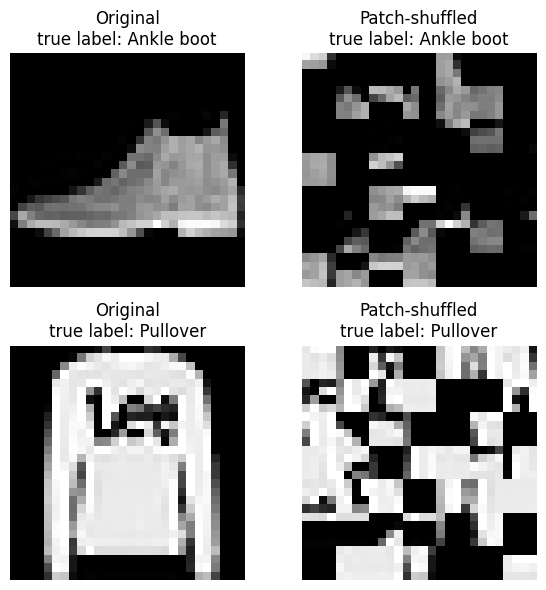

In [ ]:
class_names = test_data.classes
shuffled_images = unpatchify(shuffled_patches[:2])     # rebuild images from shuffled patches for display

fig, axes = plt.subplots(2, 2, figsize=(6, 6))
for i in range(2):
    label = class_names[test_labels[i].item()]
    axes[i, 0].imshow(test_images[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"Original\ntrue label: {label}")
    axes[i, 1].imshow(shuffled_images[i].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"Patch-shuffled\ntrue label: {label}")
    axes[i, 0].axis("off")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

## (c) Explain

**The model without positional embeddings:** Without positions, every layer is blind to patch order. The patch projection, LayerNorm and MLP act on each patch separately, so shuffling only reorders rows, and the CLS row's attention output is a softmax-weighted sum over all patches, which does not depend on the order of the terms. The CLS row is also the only row the classifier reads, so its prediction depends only on the set of patches and stays the same apart from numerical rounding, as seen in part (a) (60.93% before and after, 100% of predictions unchanged).

**The model with positional embeddings:** Here each patch embedding has a learned position vector added to it, so after shuffling a patch's content is paired with the wrong slot's position vector, and the attention scores and the CLS representation change. This model learned to use where things are (e.g. sleeves at the sides, shoes at the bottom), so scrambled layouts mislead it, and accuracy fell from 76.73% to 17.98%.

## Note on AI tool usage

We used ChatGPT and Claude as support tools. We used them to check our understanding of the questions, to verify the results we obtained, and to discuss possible explanations for those results. We also took help from these tools for parts of the code, mainly the plotting and visualisation code. We ran all the code ourselves, checked the outputs, and wrote the final explanations ourselves.